In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
import shutil, os

drive.mount('/content/drive')

project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

# copy the raw dataset into your Drive project folder
shutil.copy('/content/Dataset for ML - ML.csv', f'{project_dir}/Dataset for ML - ML.csv')
print(f"Saved raw dataset to {project_dir}/Dataset for ML - ML.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved raw dataset to /content/drive/MyDrive/scandium_leaching_project/Dataset for ML - ML.csv


In [ ]:
import pandas as pd
import os

# 1. Load
df = pd.read_csv('/content/Dataset for ML - ML.csv', header=1)
df = df.drop(df.columns[-1], axis=1)  # drop the reference column

# 2. Standardize missing markers BEFORE counting NaNs
df = df.replace(['Nan', 'nan', 'NAN', 'not mentioned', ''], pd.NA)

# 3. Check missingness
total_rows = len(df)
print("Total rows:", total_rows)

nan_pct = (df.isna().sum() / total_rows * 100).round(1).sort_values(ascending=False)
print(nan_pct)

# 4. Drop high-missing columns based on what you just saw
df = df.drop(columns=["Maximum feed particle size (μm)", "Pulp density"])

# 5. NOW save — after cleaning is actually done
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)
df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)

Total rows: 310
Pulp density                       92.9
Maximum feed particle size (μm)    91.6
Acid 2 pKa                         89.7
Acid 2 Smiles                      82.6
Acid 2 Concentration(mol/L)        82.6
H2O2 concentration (vol %)         81.9
Initial Sc2O3 (wt. %)               8.7
Acid pKa                            0.3
Acid type                           0.3
Acid Smiles                         0.3
Acid Concentration(mol/L)           0.0
Leaching agent pKa                  0.0
Leaching agent SMILES               0.0
Temperature (°C)                    0.0
Time(min)                           0.0
L/S ratio(mL/g)                     0.0
Leaching efficiency (%)             0.0
dtype: float64


In [ ]:
# --- Acid 2 concentration: NaN -> 0 (means "no second acid used") ---
df['Acid 2 Concentration(mol/L)'] = pd.to_numeric(df['Acid 2 Concentration(mol/L)'], errors='coerce').fillna(0)

# --- flag: was a second acid actually used? ---
df['has_acid2'] = (df['Acid 2 Concentration(mol/L)'] > 0).astype(int)

# --- Acid 2 pKa: keep as NaN when acid 2 isn't present (has_acid2 flag explains why) ---
df['Acid 2 pKa'] = pd.to_numeric(df['Acid 2 pKa'], errors='coerce')

# --- H2O2: same logic as concentration, 0 means "not used" ---
df['H2O2 concentration (vol %)'] = pd.to_numeric(df['H2O2 concentration (vol %)'], errors='coerce').fillna(0)

# sanity checks
print("Acid 2 Concentration NaNs:", df['Acid 2 Concentration(mol/L)'].isna().sum())  # should be 0
print("Acid 2 pKa NaNs:", df['Acid 2 pKa'].isna().sum())  # should equal count where has_acid2 == 0
print("has_acid2 counts:\n", df['has_acid2'].value_counts())
print("H2O2 NaNs:", df['H2O2 concentration (vol %)'].isna().sum())  # should be 0

# --- save to Drive (last step) ---
import os

project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Acid 2 Concentration NaNs: 0
Acid 2 pKa NaNs: 278
has_acid2 counts:
 has_acid2
0    278
1     32
Name: count, dtype: int64
H2O2 NaNs: 0
Saved to /content/drive/MyDrive/scandium_leaching_project/cleaned_dataset.csv


In [ ]:
import re
import numpy as np
import os

# --- 1. Standardize 'Nan'/'nan'/etc. across the WHOLE dataframe first ---
df = df.replace(['Nan', 'nan', 'NAN', 'NaN', 'not mentioned', 'Not mentioned', ''], np.nan)

# --- 2. Standardize units in Acid Concentration (strip 'mol/L', 'M', 'mol L-1', etc.) ---
def clean_concentration(val):
    """Extract just the numeric value, stripping any unit text."""
    if pd.isna(val):
        return np.nan
    val = str(val)
    match = re.search(r"[-+]?\d*\.?\d+", val)  # first numeric token in the string
    return float(match.group()) if match else np.nan

# --- 3. Detect swapped values: Acid Smiles column holding a pure number
#         (i.e. it should be in Acid Concentration instead) ---
def looks_purely_numeric(val):
    """True if the string is basically just a number (possibly with units), not a SMILES string."""
    if pd.isna(val):
        return False
    val = str(val).strip()
    return bool(re.fullmatch(r"[-+]?\d*\.?\d+\s*(mol/?L|mol\s*L-?1|M)?", val, re.IGNORECASE))

swap_mask = df['Acid Smiles'].apply(looks_purely_numeric)
print(f"Rows with swapped Acid Smiles / Acid Concentration: {swap_mask.sum()}")
print(df.loc[swap_mask, ['Acid Smiles', 'Acid Concentration(mol/L)']])

# perform the swap for those rows
swapped_smiles = df.loc[swap_mask, 'Acid Concentration(mol/L)'].copy()
swapped_conc = df.loc[swap_mask, 'Acid Smiles'].copy()

df.loc[swap_mask, 'Acid Smiles'] = swapped_smiles
df.loc[swap_mask, 'Acid Concentration(mol/L)'] = swapped_conc

# --- 4. Now that values are in the right columns, clean the numeric column properly ---
df['Acid Concentration(mol/L)'] = df['Acid Concentration(mol/L)'].apply(clean_concentration)

# sanity checks
print("\nAcid Concentration stats after cleaning:")
print(df['Acid Concentration(mol/L)'].describe())

remaining_numeric = df['Acid Smiles'].apply(looks_purely_numeric)
print(f"\nAny numeric-looking values still in Acid Smiles: {remaining_numeric.sum()}")

# --- 5. Save to Drive (last step, after all cleaning above) ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Rows with swapped Acid Smiles / Acid Concentration: 10
    Acid Smiles Acid Concentration(mol/L)
154        2.98      OC(=O)C(O)C(O)C(=O)O
155        2.98      OC(=O)C(O)C(O)C(=O)O
156        2.98      OC(=O)C(O)C(O)C(=O)O
157        2.98      OC(=O)C(O)C(O)C(=O)O
158        2.98      OC(=O)C(O)C(O)C(=O)O
159        2.98      OC(=O)C(O)C(O)C(=O)O
160        2.98      OC(=O)C(O)C(O)C(=O)O
161        2.98      OC(=O)C(O)C(O)C(=O)O
162        2.98      OC(=O)C(O)C(O)C(=O)O
163        2.98      OC(=O)C(O)C(O)C(=O)O

Acid Concentration stats after cleaning:
count    310.000000
mean       4.840274
std        3.051147
min        0.000000
25%        2.980000
50%        5.000000
75%        6.600000
max       18.000000
Name: Acid Concentration(mol/L), dtype: float64

Any numeric-looking values still in Acid Smiles: 0
Saved to /content/drive/MyDrive/scandium_leaching_project/cleaned_dataset.csv


In [ ]:
import pandas as pd
import os

# --- check number of unique categories in Acid type ---
print("Unique Acid type categories:", df['Acid type'].nunique())
print(df['Acid type'].value_counts(dropna=False))

# --- one-hot encode Acid type ---
df = pd.get_dummies(df, columns=['Acid type'], prefix='Acid', dummy_na=True)

# sanity check — new columns created
print("\nNew one-hot columns:")
print([c for c in df.columns if c.startswith('Acid_')])

# --- save to Drive (last step) ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Unique Acid type categories: 14
Acid type
Sulfuric acid                         87
H₂SO₄                                 51
H₂SO₄ (5% CaF₂)                       40
Nitric acid                           27
HCL                                   22
Brønsted acidic ionic liquid          22
Only H₂SO₄ (no CaF₂)                  20
Citric acid + EDTA + tartaric acid    10
Hydrochloric acid                      9
H₂SO₄                                  5
H₂SO₄ + 5% CaF₂                        5
H₂SO₄ + 2.5% CaF₂                      5
H₂SO₄ + 7.5% CaF₂                      5
(6 M H₂SO₄ + 5% CaF₂)                  1
NaN                                    1
Name: count, dtype: int64

New one-hot columns:
['Acid_(6 M H₂SO₄ + 5% CaF₂)', 'Acid_Brønsted acidic ionic liquid', 'Acid_Citric acid + EDTA + tartaric acid', 'Acid_HCL', 'Acid_Hydrochloric acid', 'Acid_H₂SO₄', 'Acid_H₂SO₄ ', 'Acid_H₂SO₄ (5% CaF₂)', 'Acid_H₂SO₄ + 2.5% CaF₂', 'Acid_H₂SO₄ + 5% CaF₂', 'Acid_H₂SO₄ + 7.5% CaF₂', 'Acid_Nitric acid

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import os

# --- identify numeric columns to scale ---
# EXCLUDE: the target variable, binary flags, and one-hot encoded columns (0/1 already)
target_col = 'Leaching efficiency (%)'

exclude_cols = [target_col, 'has_acid2'] + [c for c in df.columns if c.startswith('Acid_')]

numeric_cols = df.select_dtypes(include='number').columns.tolist()
cols_to_scale = [c for c in numeric_cols if c not in exclude_cols]

print("Columns being scaled:")
print(cols_to_scale)

# --- fit and apply StandardScaler ---
scaler = StandardScaler()
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

# sanity check — mean ~0, std ~1 for scaled columns
print("\nPost-scaling check (mean should be ~0, std ~1):")
print(df[cols_to_scale].describe().loc[['mean', 'std']])

# --- save to Drive ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Columns being scaled:
['Acid pKa', 'Acid Concentration(mol/L)', 'Acid 2 pKa', 'Acid 2 Concentration(mol/L)', 'H2O2 concentration (vol %)', 'Temperature (°C)', 'Time(min)']

Post-scaling check (mean should be ~0, std ~1):
          Acid pKa  Acid Concentration(mol/L)    Acid 2 pKa  \
mean -2.759389e-16              -2.750488e-16  1.665335e-16   
std   1.001622e+00               1.001617e+00  1.016001e+00   

      Acid 2 Concentration(mol/L)  H2O2 concentration (vol %)  \
mean                 6.876220e-17               -8.022257e-17   
std                  1.001617e+00                1.001617e+00   

      Temperature (°C)     Time(min)  
mean     -1.031433e-16 -2.292073e-17  
std       1.001617e+00  1.001617e+00  
Saved to /content/drive/MyDrive/scandium_leaching_project/cleaned_dataset.csv


In [ ]:
from sklearn.impute import KNNImputer
import pandas as pd
import numpy as np
import os

knn_features = [
    'Initial Sc2O3 (wt. %)',
    'Acid Concentration(mol/L)',
    'Acid 2 Concentration(mol/L)',
    'Temperature (°C)',
    'Time(min)',
    'L/S ratio(mL/g)',
]

# force conversion: pd.NA -> np.nan, and ensure proper float dtype
subset = df[knn_features].apply(pd.to_numeric, errors='coerce').astype(float)

imputer = KNNImputer(n_neighbors=3)
imputed_values = imputer.fit_transform(subset)

df['Initial Sc2O3 (wt. %)'] = imputed_values[:, knn_features.index('Initial Sc2O3 (wt. %)')]

# sanity check
print("Remaining NaNs in Initial Sc2O3:", df['Initial Sc2O3 (wt. %)'].isna().sum())
print(df['Initial Sc2O3 (wt. %)'].describe())

# --- save to Drive ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)
df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Remaining NaNs in Initial Sc2O3: 0
count    310.000000
mean       0.408498
std        0.720719
min        0.000140
25%        0.015000
50%        0.018400
75%        0.033700
max        1.920000
Name: Initial Sc2O3 (wt. %), dtype: float64
Saved to /content/drive/MyDrive/scandium_leaching_project/cleaned_dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import re
import os

# --- 1. Leaching efficiency: strip '%' signs, flag anything impossible (>100) ---
df['Leaching efficiency (%)'] = df['Leaching efficiency (%)'].astype(str).str.replace('%', '', regex=False)
df['Leaching efficiency (%)'] = pd.to_numeric(df['Leaching efficiency (%)'], errors='coerce')

impossible_mask = df['Leaching efficiency (%)'] > 100
print(f"Rows with efficiency > 100% (likely typo): {impossible_mask.sum()}")
print(df.loc[impossible_mask, ['Leaching efficiency (%)']])

# treat impossible values as missing — go back to source paper if you want the real value
df.loc[impossible_mask, 'Leaching efficiency (%)'] = np.nan

print("\nLeaching efficiency range after cleaning:")
print(df['Leaching efficiency (%)'].describe())

# --- 2. L/S ratio: convert any 'X:Y' style values into a plain decimal ---
def fix_ls_ratio(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip()
    if ':' in val:
        parts = val.split(':')
        try:
            num, denom = float(parts[0]), float(parts[1])
            return num if denom == 0 else num / denom if denom != 1 else num
            # NOTE: if your ':' values genuinely mean liquid:solid e.g. '5:1' -> 5 (as ratio value),
            # adjust this logic based on what the papers actually intended.
        except (ValueError, ZeroDivisionError):
            return np.nan
    try:
        return float(val)
    except ValueError:
        return np.nan

df['L/S ratio(mL/g)'] = df['L/S ratio(mL/g)'].apply(fix_ls_ratio)

print("\nL/S ratio unique values after cleaning:")
print(sorted(df['L/S ratio(mL/g)'].dropna().unique()))

# --- save to Drive ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)
df.to_csv(f'{project_dir}/cleaned_dataset.csv', index=False)
print(f"Saved to {project_dir}/cleaned_dataset.csv")

Rows with efficiency > 100% (likely typo): 1
    Leaching efficiency (%)
21                   9200.0

Leaching efficiency range after cleaning:
count    308.000000
mean      65.176071
std       28.203920
min        1.000000
25%       45.000000
50%       70.555000
75%       91.000000
max      100.000000
Name: Leaching efficiency (%), dtype: float64

L/S ratio unique values after cleaning:
[np.float64(0.0), np.float64(1.0), np.float64(1.8), np.float64(2.0), np.float64(2.2), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(30.0)]
Saved to /content/drive/MyDrive/scandium_leaching_project/cleaned_dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import joblib
import os
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 1. Select only the specified features ---
target_col = 'Leaching efficiency (%)'

acid_dummy_cols = [c for c in df.columns if c.startswith('Acid_')]

base_features = [
    'Initial Sc2O3 (wt. %)',
    'Time(min)',
    'Temperature (°C)',
    'L/S ratio(mL/g)',
    'Acid pKa',
    'Acid Concentration(mol/L)',
    'H2O2 concentration (vol %)',
    'has_acid2',
    'Acid 2 pKa',
    'Acid 2 Concentration(mol/L)',
]
feature_cols = base_features + acid_dummy_cols

df_model = df.dropna(subset=[target_col]).copy()
X = df_model[feature_cols]
y = df_model[target_col]

print("Feature columns:", X.columns.tolist())
print("X shape:", X.shape, "y shape:", y.shape)
print("\nNaNs remaining in X:\n", X.isna().sum()[X.isna().sum() > 0])
print("Non-numeric columns remaining:", X.select_dtypes(include='object').columns.tolist())

# --- 2. Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

# --- 3. 5-fold CV ---
rf = RandomForestRegressor(n_estimators=300, random_state=42)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(rf, X_train, y_train, cv=kf, scoring='r2')
cv_mae = -cross_val_score(rf, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error')
print(f"\n5-fold CV R2:  {cv_r2.mean():.3f} (+/- {cv_r2.std():.3f})")
print(f"5-fold CV MAE: {cv_mae.mean():.3f} (+/- {cv_mae.std():.3f})")

# --- 4. Fit on full training set, evaluate on held-out test set ---
rf.fit(X_train, y_train)
preds = rf.predict(X_test)

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)
print(f"\nHeld-out test performance -> MAE: {mae:.3f}, RMSE: {rmse:.3f}, R2: {r2:.3f}")

# --- 5. Feature importances ---
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature importances:\n", importances)

# --- 6. Save to Drive ---
project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

joblib.dump(rf, f'{project_dir}/random_forest_model.pkl')
df_model[feature_cols + [target_col]].to_csv(f'{project_dir}/final_model_dataset.csv', index=False)

results_summary = pd.DataFrame({
    'CV_R2_mean': [cv_r2.mean()], 'CV_R2_std': [cv_r2.std()],
    'CV_MAE_mean': [cv_mae.mean()], 'CV_MAE_std': [cv_mae.std()],
    'Test_MAE': [mae], 'Test_RMSE': [rmse], 'Test_R2': [r2],
})
results_summary.to_csv(f'{project_dir}/model_results.csv', index=False)
importances.to_csv(f'{project_dir}/feature_importances.csv')

print(f"\nSaved model, results, feature importances, and final dataset to {project_dir}")

Feature columns: ['Initial Sc2O3 (wt. %)', 'Time(min)', 'Temperature (°C)', 'L/S ratio(mL/g)', 'Acid pKa', 'Acid Concentration(mol/L)', 'H2O2 concentration (vol %)', 'has_acid2', 'Acid 2 pKa', 'Acid 2 Concentration(mol/L)', 'Acid_(6 M H₂SO₄ + 5% CaF₂)', 'Acid_Brønsted acidic ionic liquid', 'Acid_Citric acid + EDTA + tartaric acid', 'Acid_HCL', 'Acid_Hydrochloric acid', 'Acid_H₂SO₄', 'Acid_H₂SO₄ ', 'Acid_H₂SO₄ (5% CaF₂)', 'Acid_H₂SO₄ + 2.5% CaF₂', 'Acid_H₂SO₄ + 5% CaF₂', 'Acid_H₂SO₄ + 7.5% CaF₂', 'Acid_Nitric acid', 'Acid_Only H₂SO₄ (no CaF₂)', 'Acid_Sulfuric acid', 'Acid_nan']
X shape: (308, 25) y shape: (308,)

NaNs remaining in X:
 Acid pKa        1
Acid 2 pKa    276
dtype: int64
Non-numeric columns remaining: []

Train size: 246, Test size: 62

5-fold CV R2:  0.767 (+/- 0.115)
5-fold CV MAE: 7.643 (+/- 1.412)

Held-out test performance -> MAE: 7.744, RMSE: 15.065, R2: 0.715

Feature importances:
 Initial Sc2O3 (wt. %)                      0.198110
Acid 2 pKa                         

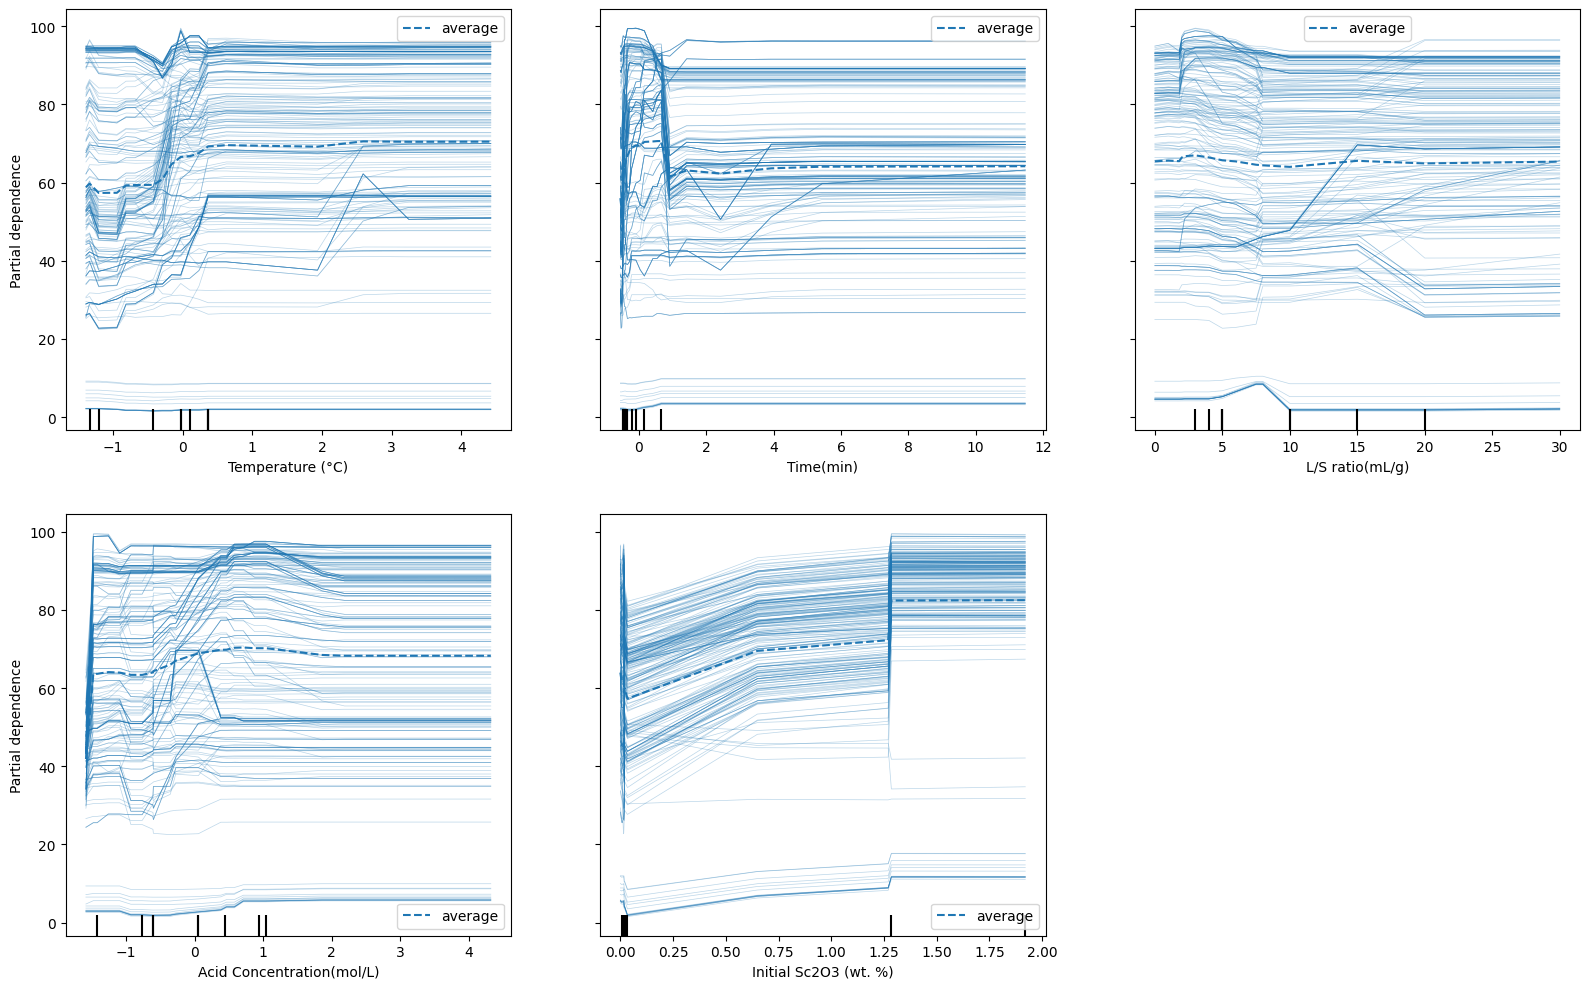

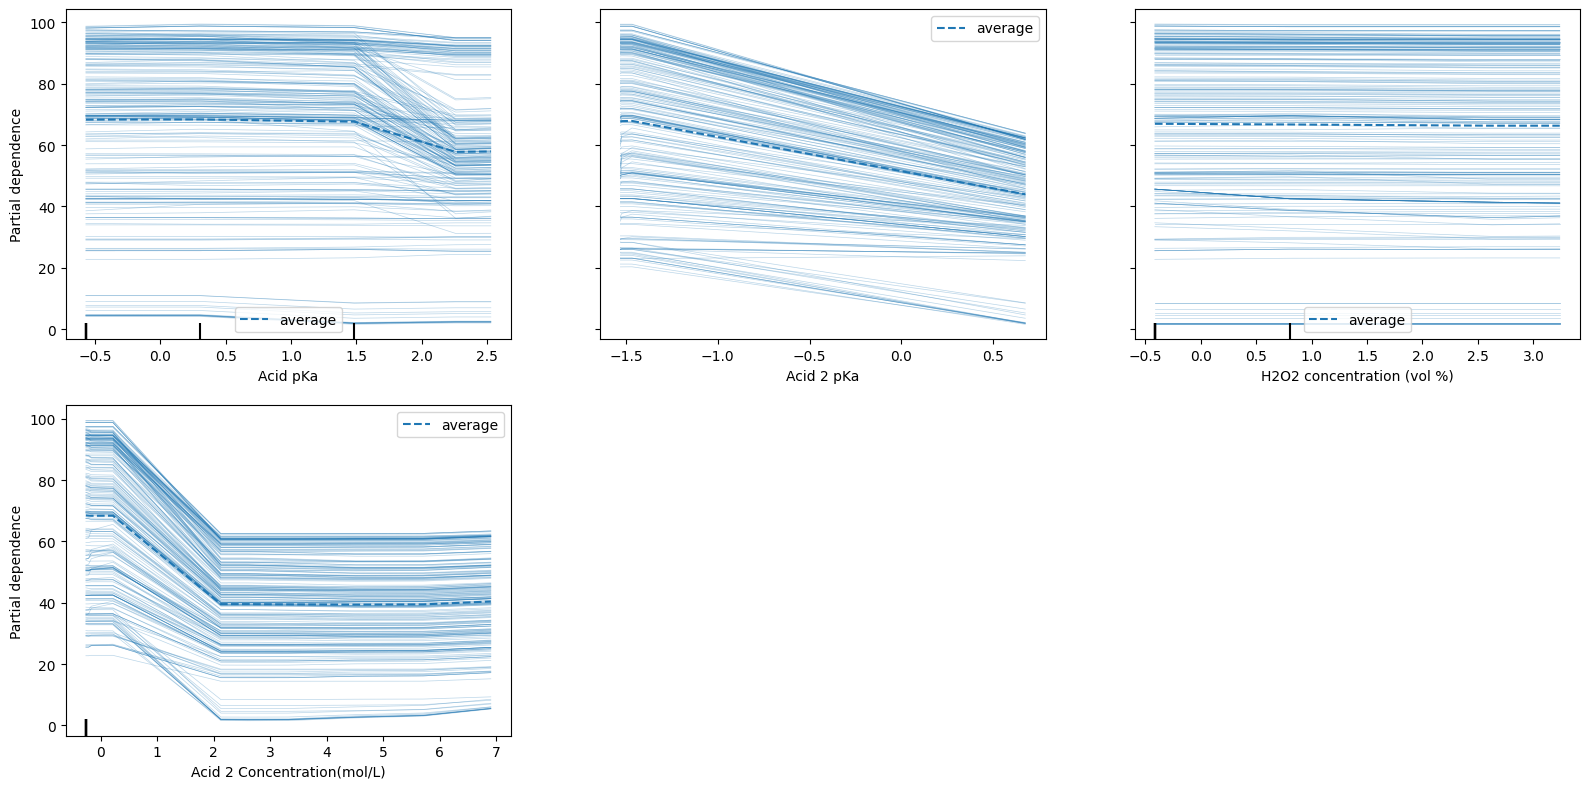

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# pick the continuous features you most want to understand
features_to_plot = [
    'Temperature (°C)',
    'Time(min)',
    'L/S ratio(mL/g)',
    'Acid Concentration(mol/L)',
    'Initial Sc2O3 (wt. %)',
]

fig, ax = plt.subplots(figsize=(16, 10))
PartialDependenceDisplay.from_estimator(
    rf,                     # your trained RandomForestRegressor
    X_train,                # training features (the data being "copied and overwritten")
    features=features_to_plot,
    kind='both',            # plots both the PDP (bold average line) AND ICE curves (thin individual lines)
    ax=ax,
    n_jobs=-1,
)
plt.tight_layout()
plt.savefig(f'{project_dir}/partial_dependence_plots.png', dpi=150)
plt.show()

# continuous features you left out
more_features = ['Acid pKa', 'Acid 2 pKa', 'H2O2 concentration (vol %)', 'Acid 2 Concentration(mol/L)']

fig, ax = plt.subplots(figsize=(16, 8))
PartialDependenceDisplay.from_estimator(
    rf, X_train, features=more_features, kind='both', ax=ax, n_jobs=-1
)
plt.tight_layout()
plt.savefig(f'{project_dir}/pdp_secondary_features.png', dpi=150)
plt.show()

In [ ]:
!pip install scikit-optimize
import numpy as np
import pandas as pd
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args

# --- continuous features to optimize (bounds come from YOUR training data's real range,
#     so we never propose conditions outside what's experimentally plausible) ---
continuous_features = [
    'Initial Sc2O3 (wt. %)', 'Time(min)', 'Temperature (°C)', 'L/S ratio(mL/g)',
    'Acid pKa', 'Acid Concentration(mol/L)', 'H2O2 concentration (vol %)',
    'Acid 2 pKa', 'Acid 2 Concentration(mol/L)',
]

search_space = [
    Real(X_train[feat].min(), X_train[feat].max(), name=feat)
    for feat in continuous_features
]

acid_dummy_cols = [c for c in X_train.columns if c.startswith('Acid_')]

def optimize_for_acid(acid_col):
    """Run Bayesian Optimization with one specific acid type fixed to 1, all others 0."""

    @use_named_args(search_space)
    def objective(**params):
        row = {feat: params[feat] for feat in continuous_features}
        row['has_acid2'] = 1 if row['Acid 2 Concentration(mol/L)'] > 0 else 0
        for col in acid_dummy_cols:
            row[col] = 1 if col == acid_col else 0
        x_df = pd.DataFrame([row])[X_train.columns]  # match training column order
        pred = rf.predict(x_df)[0]
        return -pred  # gp_minimize MINIMIZES, so negate to effectively maximize efficiency

    result = gp_minimize(
        objective,
        search_space,
        n_calls=60,          # total evaluations (budget)
        n_initial_points=15, # random points before GP kicks in
        random_state=42,
    )

    best_params = dict(zip(continuous_features, result.x))
    best_efficiency = -result.fun
    return best_params, best_efficiency

# --- run separately for each acid type present in your one-hot columns ---
results = {}
for acid_col in acid_dummy_cols:
    if acid_col in ['Acid_nan', 'Acid_']:  # skip junk/placeholder columns
        continue
    best_params, best_eff = optimize_for_acid(acid_col)
    results[acid_col] = {**best_params, 'Predicted_Efficiency': best_eff}
    print(f"\n{acid_col} -> Predicted optimum efficiency: {best_eff:.2f}%")
    for k, v in best_params.items():
        print(f"   {k}: {v:.3f}")

results_df = pd.DataFrame(results).T
print("\nSummary across all acids:\n", results_df)

results_df.to_csv(f'{project_dir}/optimal_conditions_per_acid.csv')
print(f"\nSaved to {project_dir}/optimal_conditions_per_acid.csv")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 6.1 MB/s eta 0:00:00

Acid_(6 M H₂SO₄ + 5% CaF₂) -> Predicted optimum efficiency: 91.28%
   Initial Sc2O3 (wt. %): 1.920
   Time(min): 0.504
   Temperature (°C): 4.423
   L/S ratio(mL/g): 3.517
   Acid pKa: -0.568
   Acid Concentration(mol/L): 2.320
   H2O2 concentration (vol %): -0.412
   Acid 2 pKa: -0.862
   Acid 2 Concentration(mol/L): -0.264

Acid_Brønsted acidic ionic liquid -> Predicted optimum efficiency: 90.01%
   Initial Sc2O3 (wt. %): 1.460
   Time(min): -0.002
   Temperature (°C): 4.305
   L/S ratio(mL/g): 16.074
   Acid pKa: -0.042
   Acid Concentration(mol/L): 1.957
   H2O2 concentration (vol %): 0.145
   Acid 2 pKa: -0.943
   Acid 2 Concentration(mol/L): 0.672

Acid_Citric acid + EDTA + tartaric acid -> Predicted optimum efficiency: 89.03%
   Initial Sc2O3 (wt. %): 1.920
   Time(min): 0.522
   Temperature (°C): -0.153
   L/S ratio(mL/g): 4.678
   Acid pKa: -0.023
   Acid Concentration(mol/L): 3.615
   H2O2 concen

In [ ]:
import os

project_dir = '/content/drive/MyDrive/scandium_leaching_project'
os.makedirs(project_dir, exist_ok=True)

# 1. The optimal conditions per acid (main result — already in the optimization code, but re-confirm it ran)
results_df.to_csv(f'{project_dir}/optimal_conditions_per_acid.csv')

# 2. The PDP plots, if you haven't saved them yet from the earlier step
#    (already included in that code block via plt.savefig, just confirming path)
# f'{project_dir}/partial_dependence_plots.png'

print("Saved optimal conditions to:", f'{project_dir}/optimal_conditions_per_acid.csv')
print("Contents of project folder:")
for f in os.listdir(project_dir):
    print(" -", f)

Saved optimal conditions to: /content/drive/MyDrive/scandium_leaching_project/optimal_conditions_per_acid.csv
Contents of project folder:
 - cleaned_dataset.csv
 - random_forest_model.pkl
 - final_model_dataset.csv
 - model_results.csv
 - feature_importances.csv
 - Dataset for ML - ML.csv
 - partial_dependence_plots.png
 - pdp_secondary_features.png
 - optimal_conditions_per_acid.csv
